# 03 — OCR evaluation: how much does OCR noise hurt?
**Requires:** `ocr_gold_datasets.py` finished (columns `text_surya`, `text_easyocr`, `text_ocr` in `processed/bhm.csv` and `processed/mimosa.csv`), notebook 01 features, notebook 02 results.

What this notebook does:
1. **E1 — OCR quality:** CER / WER of Surya, EasyOCR and Surya+fallback against the gold captions (no GPU).
2. **Auto model selection:** picks the best text-using model from notebook 02 by **validation** macro-F1 (not test, to avoid selection bias), and reuses notebook 02's hyperparameters.
3. **E2 — Effect on detection:** for each task × seed, trains the model twice —
   - on **gold** text → tested on gold, Surya, EasyOCR and OCR text (the realistic "trained on clean captions, deployed on OCR" scenario)
   - on **OCR** text → tested on the same four text versions
4. **Noise-level analysis:** macro-F1 by CER bucket + figure.
5. Paired t-tests over seeds for every drop.

Kernel: **Python (internship1)** · needs `pip install rapidfuzz`

**Runtime:** ~4–5 h with `INCLUDE_TEXT_ONLY = True` (best fusion + its text-only version), ~2–2.5 h if `False`. Resumable.

## 1. Imports & config

In [1]:
import os, re, gc, json, time, random, platform, unicodedata
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less fragmentation on 8 GB GPUs (must be set before importing torch)
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import transformers, sklearn
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import ttest_rel
from rapidfuzz.distance import Levenshtein
import matplotlib.pyplot as plt

ROOT = "/mnt/f415dcc8-27a5-4e66-8493-25f1d939974c/internshipwork/journal"
P, FEAT = f"{ROOT}/processed", f"{ROOT}/features"
NB02 = f"{ROOT}/results/02_finetuned"
RES = f"{ROOT}/results/03_ocr_eval"
PRED = f"{RES}/preds"
os.makedirs(PRED, exist_ok=True)

DATASETS = ["bhm", "mimosa"]                       # datasets that have gold captions
TASKS = [("bhm", "label"), ("mimosa", "label"), ("mimosa", "label_bin")]
SEEDS = [42, 43, 44, 45, 46]
TRAIN_SOURCES = {"gold": "text", "ocr": "text_ocr"}
TEST_SOURCES = {"gold": "text", "surya": "text_surya", "easyocr": "text_easyocr", "ocr": "text_ocr"}
INCLUDE_TEXT_ONLY = True      # also run the text-only version of the selected encoder
TEXT_MODELS = {"BanglaBERT": "csebuetnlp/banglabert", "XLM-R": "xlm-roberta-base"}
EVAL_BS = 64
FREEZE_WORD_EMB = True        # freeze only the word-embedding table (XLM-R: 192M of 278M params) to fit an 8 GB GPU;
                              # all transformer layers + head stay trainable. Applied identically to every run here.

dev = "cuda"
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(torch.cuda.get_device_name(0), "| AMP:", AMP_DTYPE)
free, total = torch.cuda.mem_get_info()
print(f"GPU memory free: {free / 2**30:.2f} / {total / 2**30:.2f} GiB  (need ~6 GiB free; close other GPU programs if lower)")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def slug(s):
    return s.replace(" ", "_").replace("+", "_").replace("(", "").replace(")", "")

NVIDIA GeForce RTX 3050 | AMP: torch.bfloat16
GPU memory free: 5.89 / 7.66 GiB  (need ~6 GiB free; close other GPU programs if lower)


## 2. Reuse notebook 02 hyperparameters

In [2]:
cfg02 = json.load(open(f"{NB02}/config.json"))["text"]
MAX_LEN, BS = cfg02["max_len"], cfg02["batch_size"]
MAX_EPOCHS, PATIENCE = cfg02["max_epochs"], cfg02["patience"]
LR_ENC, LR_HEAD, WD = cfg02["lr_encoder"], cfg02["lr_head"], cfg02["weight_decay"]
WARMUP, DROPOUT = cfg02["warmup"], cfg02["dropout"]
print({k: cfg02[k] for k in ["max_len", "batch_size", "max_epochs", "patience", "lr_encoder", "lr_head"]})

{'max_len': 128, 'batch_size': 16, 'max_epochs': 5, 'patience': 2, 'lr_encoder': 2e-05, 'lr_head': 0.0005}


## 3. Auto-select the best model from notebook 02 (by validation macro-F1)

In [3]:
r02 = pd.read_csv(f"{NB02}/runs.csv")
task_keys = {f"{d}|{t}" for d, t in TASKS}
r02["tk"] = r02["dataset"] + "|" + r02["task"]
cand = r02[~r02["model"].str.startswith("Image") & r02["tk"].isin(task_keys)]
sel = (cand.groupby("model")
           .agg(val_f1=("val_f1", "mean"), test_f1=("test_f1", "mean"), runs=("val_f1", "size"))
           .sort_values("val_f1", ascending=False))
print(sel.round(4))

def parse(name):
    use_img = name.startswith("Fusion")
    key = name.split(" ", 1)[1].replace("+CLIP", "")
    assert key in TEXT_MODELS, f"unknown encoder in model name: {name}"
    return key, use_img

BEST = sel.index[0]
best_key, best_img = parse(BEST)
MODELS = [(BEST, best_key, best_img)]
if INCLUDE_TEXT_ONLY and best_img:
    MODELS.append((f"Text-FT {best_key}", best_key, False))
print("\nSelected:", BEST, "| encoder:", best_key, "| uses image:", best_img)
print("Models to run:", [m[0] for m in MODELS])

                        val_f1  test_f1  runs
model                                        
Fusion XLM-R+CLIP       0.7643   0.7697    15
Fusion BanglaBERT+CLIP  0.7627   0.7567    15
Text-FT BanglaBERT      0.7066   0.6759    15
Text-FT XLM-R           0.7015   0.6919    15

Selected: Fusion XLM-R+CLIP | encoder: XLM-R | uses image: True
Models to run: ['Fusion XLM-R+CLIP', 'Text-FT XLM-R']


## 4. Load data (gold + OCR text) and CLIP image features

In [4]:
data = {}
for ds in DATASETS:
    df = pd.read_csv(f"{P}/{ds}.csv").fillna("")
    missing = [c for c in TEST_SOURCES.values() if c not in df.columns]
    assert not missing, f"{ds}: columns {missing} missing - run ocr_gold_datasets.py first"
    for c in TEST_SOURCES.values():
        df[c] = df[c].astype(str)
    img = np.load(f"{FEAT}/{ds}_img.npy").astype(np.float32)
    assert len(df) == len(img), f"row mismatch in {ds}"
    data[ds] = {"df": df, "img": img}
    print(ds, df.shape, "| empty OCR:", (df["text_ocr"].str.strip() == "").sum())

def idx_of(df, s):
    return np.where(df["split"].values == s)[0]

for ds, lab in TASKS:
    df = data[ds]["df"]
    np.save(f"{PRED}/{ds}__{lab}__ytrue.npy", df[lab].values[idx_of(df, "test")].astype(int))

bhm (7109, 10) | empty OCR: 8
mimosa (4848, 9) | empty OCR: 0


## 5. E1 — OCR quality (CER / WER vs. gold captions)

In [5]:
def norm(s):
    s = unicodedata.normalize("NFC", str(s)).lower()
    s = re.sub(r"[^\u0980-\u09FFa-z0-9\s]", " ", s)      # drop punctuation / symbols
    return re.sub(r"\s+", " ", s).strip()

ENGINES = {"surya": "text_surya", "easyocr": "text_easyocr", "surya+fallback": "text_ocr"}
rows = []
for ds in DATASETS:
    df = data[ds]["df"]
    ref = df["text"].map(norm)
    ok = (ref.str.len() > 0).values
    for eng, col in ENGINES.items():
        hyp = df[col].map(norm)
        cd = np.array([Levenshtein.distance(a, b) for a, b in zip(ref[ok], hyp[ok])])
        wd = np.array([Levenshtein.distance(a.split(), b.split()) for a, b in zip(ref[ok], hyp[ok])])
        rl = ref[ok].str.len().values
        wl = ref[ok].str.split().str.len().values
        cer = np.full(len(df), np.nan); cer[ok] = cd / rl
        df[f"cer_{col}"] = cer
        test = ok & (df["split"].values == "test")
        rows.append({"dataset": ds, "engine": eng, "n": int(ok.sum()),
                     "CER": cd.sum() / rl.sum(), "WER": wd.sum() / wl.sum(),
                     "CER_median": float(np.median(cd / rl)),
                     "CER_test": float(np.nansum(cer[test] * df["text"].map(norm).str.len().values[test])
                                       / df["text"].map(norm).str.len().values[test].sum()),
                     "empty_ocr_%": 100 * float((hyp[ok] == "").mean())})

cer_df = pd.DataFrame(rows)
cer_df.round(4)

,dataset,engine,n,CER,WER,CER_median,CER_test,empty_ocr_%
0,bhm,surya,7109,0.2994,0.3646,0.1875,0.2730,0.4642
1,bhm,easyocr,7109,0.3730,0.5565,0.2708,0.3349,0.1407
2,bhm,surya+fallback,7109,0.2984,0.3640,0.1871,0.2715,0.1125
3,mimosa,surya,4848,0.3875,0.4665,0.2599,0.3557,0.6807
4,mimosa,easyocr,4848,0.4255,0.5949,0.3056,0.3983,0.0000
5,mimosa,surya+fallback,4848,0.3855,0.4654,0.2584,0.3541,0.0619


## 6. Model + training code (same as notebook 02, text column selectable)

In [6]:
class MemeDS(Dataset):
    def __init__(self, enc, img, y, idx):
        idx = torch.from_numpy(idx)
        self.ids, self.mask = enc["input_ids"][idx], enc["attention_mask"][idx]
        self.img = torch.from_numpy(img)[idx]
        self.y = torch.from_numpy(y)[idx]
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.mask[i], self.img[i], self.y[i]

class TextFusion(nn.Module):
    def __init__(self, name, n, img_dim=0):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        if FREEZE_WORD_EMB:
            self.enc.get_input_embeddings().weight.requires_grad_(False)
        h = self.enc.config.hidden_size
        self.use_img = img_dim > 0
        if self.use_img:
            self.img_proj = nn.Sequential(nn.Linear(img_dim, h), nn.GELU(), nn.Dropout(DROPOUT))
        self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(h * (2 if self.use_img else 1), h),
                                  nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(h, n))
    def forward(self, ids, mask, img=None):
        hs = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(hs.dtype)
        t = (hs * m).sum(1) / m.sum(1).clamp(min=1)
        z = torch.cat([t, self.img_proj(img)], -1) if self.use_img else t
        return self.head(z)

_tok, _enc_cache = {}, {}
def get_enc(key, ds, col):
    k = (key, ds, col)
    if k not in _enc_cache:
        if key not in _tok:
            _tok[key] = AutoTokenizer.from_pretrained(TEXT_MODELS[key])
        _enc_cache[k] = _tok[key](data[ds]["df"][col].tolist(), padding="max_length", truncation=True,
                                  max_length=MAX_LEN, return_tensors="pt")
    return _enc_cache[k]

def class_weights(y, n):
    counts = np.bincount(y, minlength=n)
    return torch.tensor(len(y) / (n * np.maximum(counts, 1)), dtype=torch.float32, device=dev)

@torch.no_grad()
def predict(model, loader, use_img):
    model.eval(); out = []
    for ids, mask, img, _ in loader:
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            lo = model(ids.to(dev), mask.to(dev), img.to(dev) if use_img else None)
        out.append(torch.softmax(lo.float(), 1).cpu())
    return torch.cat(out).numpy()

def run_train(key, ds, lab, seed, use_img, train_col):
    set_seed(seed)
    df = data[ds]["df"]; y = df[lab].values.astype(np.int64); n = int(y.max()) + 1
    img = data[ds]["img"]
    tr, va, te = [idx_of(df, s) for s in ("train", "val", "test")]
    enc_tr = get_enc(key, ds, train_col)
    g = torch.Generator().manual_seed(seed)
    dl_tr = DataLoader(MemeDS(enc_tr, img, y, tr), batch_size=BS, shuffle=True, generator=g)
    dl_va = DataLoader(MemeDS(enc_tr, img, y, va), batch_size=EVAL_BS)   # val uses the training text source

    model = TextFusion(TEXT_MODELS[key], n, img.shape[1] if use_img else 0).to(dev)
    enc_ids = {id(p) for p in model.enc.parameters()}
    head_params = [p for p in model.parameters() if id(p) not in enc_ids]
    enc_params = [p for p in model.enc.parameters() if p.requires_grad]
    opt = torch.optim.AdamW([{"params": enc_params, "lr": LR_ENC},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WD,
                            foreach=False)          # lower peak GPU memory; identical update rule
    steps = len(dl_tr) * MAX_EPOCHS
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    lossf = nn.CrossEntropyLoss(weight=class_weights(y[tr], n))

    best_f, best_state, best_ep, bad = -1, None, 0, 0
    for ep in range(MAX_EPOCHS):
        model.train()
        for ids, mask, im, yb in tqdm(dl_tr, desc=f"{key} {ds} ep{ep + 1}", leave=False):
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                lo = model(ids.to(dev), mask.to(dev), im.to(dev) if use_img else None)
            loss = lossf(lo.float(), yb.to(dev))
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        f = f1_score(y[va], predict(model, dl_va, use_img).argmax(1), average="macro")
        if f > best_f:
            best_f, best_ep, bad = f, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    probs = {}
    for te_name, te_col in TEST_SOURCES.items():
        dl_te = DataLoader(MemeDS(get_enc(key, ds, te_col), img, y, te), batch_size=EVAL_BS)
        probs[te_name] = predict(model, dl_te, use_img)
    del model, opt, best_state, sch, scaler, dl_tr, dl_va
    gc.collect(); torch.cuda.empty_cache()
    return best_f, best_ep, probs, y[te]

## 7. E2 — train on gold / OCR text, test on every text version (long, resumable)

In [7]:
RUNS_CSV = f"{RES}/runs.csv"
if os.path.exists(RUNS_CSV) and "word_emb" not in pd.read_csv(RUNS_CSV, nrows=1).columns:
    os.rename(RUNS_CSV, f"{RES}/runs_old_unfrozen_emb.csv")
    print("Moved earlier runs (different setting) to runs_old_unfrozen_emb.csv - they are not reused.")
done = set(pd.read_csv(RUNS_CSV)["train_id"]) if os.path.exists(RUNS_CSV) else set()
print("trainings already done:", len(done))

for seed in SEEDS:
    for name, key, use_img in MODELS:
        for ds, lab in TASKS:
            for tr_name, tr_col in TRAIN_SOURCES.items():
                train_id = f"{ds}__{lab}__{slug(name)}__train-{tr_name}__s{seed}"
                if train_id in done:
                    continue
                t0 = time.time()
                for attempt in (1, 2):
                    try:
                        vf, ep, probs, y_te = run_train(key, ds, lab, seed, use_img, tr_col)
                        break
                    except torch.cuda.OutOfMemoryError:
                        gc.collect(); torch.cuda.empty_cache()
                        if attempt == 2:
                            raise
                        print(f"  out of GPU memory on {train_id} - freed memory, retrying once")
                mins = round((time.time() - t0) / 60, 2)
                rows = []
                for te_name, p in probs.items():
                    np.save(f"{PRED}/{train_id}__test-{te_name}.npy", p)
                    pred = p.argmax(1)
                    rows.append({"train_id": train_id, "dataset": ds, "task": lab, "model": name, "seed": seed,
                                 "train_text": tr_name, "test_text": te_name, "best_epoch": ep, "val_f1": vf,
                                 "test_f1": f1_score(y_te, pred, average="macro"),
                                 "test_acc": accuracy_score(y_te, pred), "minutes": mins,
                                 "word_emb": "frozen" if FREEZE_WORD_EMB else "trainable"})
                pd.DataFrame(rows).to_csv(RUNS_CSV, mode="a", header=not os.path.exists(RUNS_CSV), index=False)
                done.add(train_id)
                print(f"{ds:7s} {lab:10s} {name:20s} train={tr_name:4s} seed {seed} | " +
                      "  ".join(f"{r['test_text']}={r['test_f1']:.4f}" for r in rows) + f"  ({mins} min)")

Moved earlier runs (different setting) to runs_old_unfrozen_emb.csv - they are not reused.
trainings already done: 0


XLM-R bhm ep1:   0%|          | 0/360 [00:00<?, ?it/s]

XLM-R bhm ep2:   0%|          | 0/360 [00:00<?, ?it/s]

XLM-R bhm ep3:   0%|          | 0/360 [00:00<?, ?it/s]

bhm     label      Fusion XLM-R+CLIP    train=gold seed 42 | gold=0.7062  surya=0.6894  easyocr=0.7012  ocr=0.6894  (3.11 min)


XLM-R bhm ep1:   0%|          | 0/360 [00:00<?, ?it/s]

... (336 outputs left out)

XLM-R mimosa ep3:   0%|          | 0/213 [00:00<?, ?it/s]

XLM-R mimosa ep4:   0%|          | 0/213 [00:00<?, ?it/s]

XLM-R mimosa ep5:   0%|          | 0/213 [00:00<?, ?it/s]

mimosa  label_bin  Text-FT XLM-R        train=ocr  seed 46 | gold=0.7303  surya=0.7369  easyocr=0.7293  ocr=0.7435  (2.94 min)


## 8. Results table + drop vs. gold (paired t-test over seeds)

In [8]:
runs = pd.read_csv(RUNS_CSV)
s = (runs.groupby(["dataset", "task", "model", "train_text", "test_text"])["test_f1"]
         .agg(["mean", "std", "count"]).reset_index())
s["f1"] = s.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}" if r["count"] > 1 else f"{r['mean']:.4f}", axis=1)
main = s.pivot_table(index=["dataset", "task", "model", "train_text"], columns="test_text",
                     values="f1", aggfunc="first")
main = main[[c for c in TEST_SOURCES if c in main.columns]]
print("seeds per cell:", s["count"].min(), "-", s["count"].max())
main

seeds per cell: 5 - 5


test_text                                                  gold  \
dataset task      model             train_text                    
bhm     label     Fusion XLM-R+CLIP gold        0.7187 ± 0.0121   
                                    ocr         0.7098 ± 0.0243   
                  Text-FT XLM-R     gold        0.6709 ± 0.0081   
                                    ocr         0.6466 ± 0.0062   
mimosa  label     Fusion XLM-R+CLIP gold        0.7767 ± 0.0083   
                                    ocr         0.7529 ± 0.0060   
                  Text-FT XLM-R     gold        0.6709 ± 0.0054   
                                    ocr         0.6477 ± 0.0117   
        label_bin Fusion XLM-R+CLIP gold        0.8132 ± 0.0130   
                                    ocr         0.7990 ± 0.0139   
                  Text-FT XLM-R     gold        0.7503 ± 0.0115   
                                    ocr         0.7211 ± 0.0157   

test_text                                                 surya  \
dataset task      model             train_text                    
bhm     label     Fusion XLM-R+CLIP gold        0.7084 ± 0.0156   
                                    ocr         0.7119 ± 0.0128   
                  Text-FT XLM-R     gold        0.6345 ± 0.0061   
                                    ocr         0.6609 ± 0.0058   
mimosa  label     Fusion XLM-R+CLIP gold        0.7394 ± 0.0101   
                                    ocr         0.7648 ± 0.0045   
                  Text-FT XLM-R     gold        0.6238 ± 0.0089   
                                    ocr         0.6859 ± 0.0099   
        label_bin Fusion XLM-R+CLIP gold        0.7935 ± 0.0129   
                                    ocr         0.7982 ± 0.0110   
                  Text-FT XLM-R     gold        0.7041 ± 0.0043   
                                    ocr         0.7321 ± 0.0177   

test_text                                               easyocr  \
dataset task      model             train_text                    
bhm     label     Fusion XLM-R+CLIP gold        0.7052 ± 0.0261   
                                    ocr         0.7139 ± 0.0142   
                  Text-FT XLM-R     gold        0.6182 ± 0.0106   
                                    ocr         0.6353 ± 0.0081   
mimosa  label     Fusion XLM-R+CLIP gold        0.7379 ± 0.0061   
                                    ocr         0.7366 ± 0.0075   
                  Text-FT XLM-R     gold        0.6143 ± 0.0095   
                                    ocr         0.6429 ± 0.0096   
        label_bin Fusion XLM-R+CLIP gold        0.7611 ± 0.0064   
                                    ocr         0.7875 ± 0.0098   
                  Text-FT XLM-R     gold        0.6791 ± 0.0157   
                                    ocr         0.7077 ± 0.0177   

test_text                                                   ocr  
dataset task      model             train_text                   
bhm     label     Fusion XLM-R+CLIP gold        0.7084 ± 0.0156  
                                    ocr         0.7119 ± 0.0128  
                  Text-FT XLM-R     gold        0.6339 ± 0.0054  
                                    ocr         0.6621 ± 0.0058  
mimosa  label     Fusion XLM-R+CLIP gold        0.7409 ± 0.0095  
                                    ocr         0.7654 ± 0.0041  
                  Text-FT XLM-R     gold        0.6250 ± 0.0088  
                                    ocr         0.6865 ± 0.0099  
        label_bin Fusion XLM-R+CLIP gold        0.7955 ± 0.0135  
                                    ocr         0.7993 ± 0.0116  
                  Text-FT XLM-R     gold        0.7081 ± 0.0079  
                                    ocr         0.7344 ± 0.0168

In [9]:
deg = []
for (ds, lab, m), grp in runs.groupby(["dataset", "task", "model"]):
    base = grp[(grp.train_text == "gold") & (grp.test_text == "gold")].set_index("seed")["test_f1"]
    for tr in TRAIN_SOURCES:
        for te in TEST_SOURCES:
            if (tr, te) == ("gold", "gold"):
                continue
            x = grp[(grp.train_text == tr) & (grp.test_text == te)].set_index("seed")["test_f1"]
            common = base.index.intersection(x.index)
            if len(common) < 2:
                continue
            d = x[common] - base[common]
            deg.append({"dataset": ds, "task": lab, "model": m, "condition": f"train {tr} -> test {te}",
                        "f1": x[common].mean(), "delta_vs_gold": d.mean(), "delta_std": d.std(),
                        "p_value": ttest_rel(x[common], base[common]).pvalue, "n_seeds": len(common)})
deg_df = pd.DataFrame(deg, columns=["dataset", "task", "model", "condition", "f1", "delta_vs_gold",
                                   "delta_std", "p_value", "n_seeds"])
if deg_df.empty:
    print("Significance tests need at least 2 finished seeds per model - rerun this cell later.")
deg_df["significant(p<0.05)"] = deg_df["p_value"] < 0.05
deg_df.round(4)

,dataset,task,model,condition,f1,delta_vs_gold,delta_std,p_value,n_seeds,significant(p<0.05)
0,bhm,label,Fusion XLM-R+CLIP,train gold -> test surya,0.7084,-0.0104,0.0095,0.0703,5,False
1,bhm,label,Fusion XLM-R+CLIP,train gold -> test easyocr,0.7052,-0.0136,0.0193,0.1915,5,False
2,bhm,label,Fusion XLM-R+CLIP,train gold -> test ocr,0.7084,-0.0104,0.0095,0.0703,5,False
3,bhm,label,Fusion XLM-R+CLIP,train ocr -> test gold,0.7098,-0.0089,0.0194,0.3628,5,False
4,bhm,label,Fusion XLM-R+CLIP,train ocr -> test surya,0.7119,-0.0069,0.0130,0.3050,5,False
5,bhm,label,Fusion XLM-R+CLIP,train ocr -> test easyocr,0.7139,-0.0049,0.0163,0.5389,5,False
6,bhm,label,Fusion XLM-R+CLIP,train ocr -> test ocr,0.7119,-0.0069,0.0130,0.3050,5,False
7,bhm,label,Text-FT XLM-R,train gold -> test surya,0.6345,-0.0365,0.0133,0.0036,5,True
8,bhm,label,Text-FT XLM-R,train gold -> test easyocr,0.6182,-0.0528,0.0097,0.0003,5,True
9,bhm,label,Text-FT XLM-R,train gold -> test ocr,0.6339,-0.0370,0.0127,0.0029,5,True


## 9. Noise-level analysis — macro-F1 by OCR CER bucket (test set, mean over seeds)

In [10]:
BUCKETS = [("CER < 0.2", 0, 0.2), ("0.2 – 0.5", 0.2, 0.5), ("CER ≥ 0.5", 0.5, np.inf)]
CONDS = [("gold", "gold", "train gold → test gold"),
         ("gold", "ocr",  "train gold → test OCR"),
         ("ocr",  "ocr",  "train OCR → test OCR")]

brows = []
for ds, lab in TASKS:
    df = data[ds]["df"]; te = idx_of(df, "test")
    y_te = np.load(f"{PRED}/{ds}__{lab}__ytrue.npy")
    cer = df["cer_text_ocr"].values[te]
    empty = (df["text_ocr"].values[te] == "")
    masks = [("empty OCR", empty)] + [(b, (~empty) & (cer >= lo) & (cer < hi)) for b, lo, hi in BUCKETS]
    for name, _, _ in MODELS:
        for tr, tt, cname in CONDS:
            for bname, msk in masks:
                if msk.sum() < 5:
                    continue
                f1s = []
                for seed in SEEDS:
                    f = f"{PRED}/{ds}__{lab}__{slug(name)}__train-{tr}__s{seed}__test-{tt}.npy"
                    if os.path.exists(f):
                        p = np.load(f).argmax(1)
                        f1s.append(f1_score(y_te[msk], p[msk], average="macro"))
                if f1s:
                    brows.append({"dataset": ds, "task": lab, "model": name, "condition": cname,
                                  "bucket": bname, "n": int(msk.sum()), "f1_mean": np.mean(f1s), "f1_std": np.std(f1s)})
bucket_df = pd.DataFrame(brows)
bucket_df.pivot_table(index=["dataset", "task", "model", "condition"], columns="bucket",
                      values="f1_mean").round(4)

bucket                                                      0.2 – 0.5  \
dataset task      model             condition                           
bhm     label     Fusion XLM-R+CLIP train OCR → test OCR       0.7402   
                                    train gold → test OCR      0.7298   
                                    train gold → test gold     0.7478   
                  Text-FT XLM-R     train OCR → test OCR       0.7121   
                                    train gold → test OCR      0.6460   
                                    train gold → test gold     0.6838   
mimosa  label     Fusion XLM-R+CLIP train OCR → test OCR       0.7397   
                                    train gold → test OCR      0.7278   
                                    train gold → test gold     0.7492   
                  Text-FT XLM-R     train OCR → test OCR       0.6414   
                                    train gold → test OCR      0.5897   
                                    train gold → test gold     0.6536   
        label_bin Fusion XLM-R+CLIP train OCR → test OCR       0.7643   
                                    train gold → test OCR      0.7681   
                                    train gold → test gold     0.7814   
                  Text-FT XLM-R     train OCR → test OCR       0.6750   
                                    train gold → test OCR      0.6570   
                                    train gold → test gold     0.7236   

bucket                                                      CER < 0.2  \
dataset task      model             condition                           
bhm     label     Fusion XLM-R+CLIP train OCR → test OCR       0.7012   
                                    train gold → test OCR      0.7001   
                                    train gold → test gold     0.7031   
                  Text-FT XLM-R     train OCR → test OCR       0.6492   
                                    train gold → test OCR      0.6461   
                                    train gold → test gold     0.6567   
mimosa  label     Fusion XLM-R+CLIP train OCR → test OCR       0.7880   
                                    train gold → test OCR      0.7715   
                                    train gold → test gold     0.8010   
                  Text-FT XLM-R     train OCR → test OCR       0.7120   
                                    train gold → test OCR      0.6691   
                                    train gold → test gold     0.6973   
        label_bin Fusion XLM-R+CLIP train OCR → test OCR       0.8462   
                                    train gold → test OCR      0.8445   
                                    train gold → test gold     0.8551   
                  Text-FT XLM-R     train OCR → test OCR       0.7871   
                                    train gold → test OCR      0.7735   
                                    train gold → test gold     0.7953   

bucket                                                      CER ≥ 0.5  
dataset task      model             condition                          
bhm     label     Fusion XLM-R+CLIP train OCR → test OCR       0.6993  
                                    train gold → test OCR      0.6964  
                                    train gold → test gold     0.7171  
                  Text-FT XLM-R     train OCR → test OCR       0.6249  
                                    train gold → test OCR      0.5818  
                                    train gold → test gold     0.6856  
mimosa  label     Fusion XLM-R+CLIP train OCR → test OCR       0.7475  
                                    train gold → test OCR      0.7024  
                                    train gold → test gold     0.7612  
                  Text-FT XLM-R     train OCR → test OCR       0.6795  
                                    train gold → test OCR      0.5848  
                                    train gold → test gold     0.6410  
        label_bin Fusion XLM-R+CLIP train OCR → test OCR       0.7610 

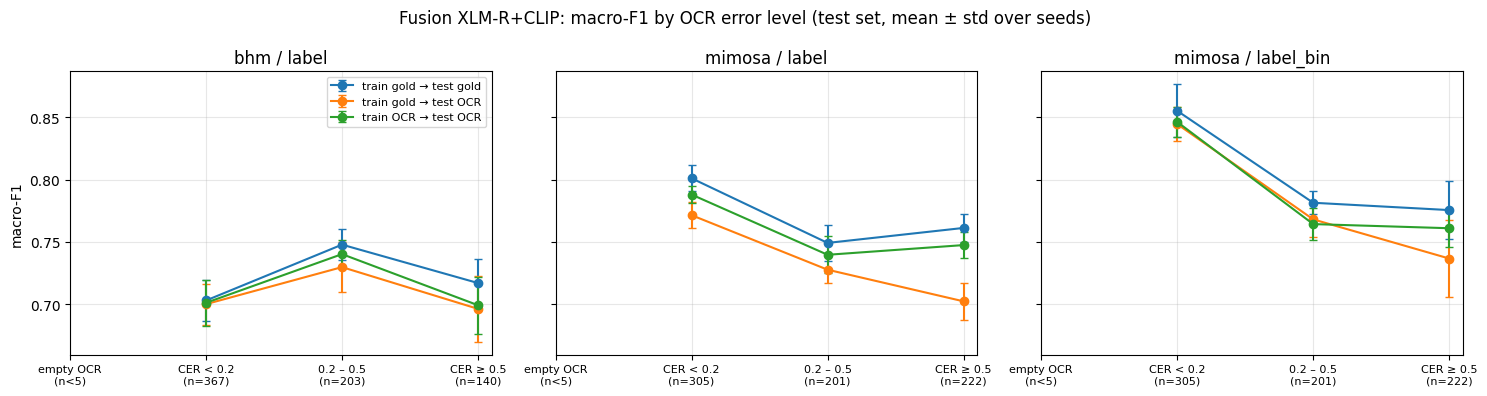

In [11]:
order = ["empty OCR"] + [b for b, _, _ in BUCKETS]
best = MODELS[0][0]
fig, axes = plt.subplots(1, len(TASKS), figsize=(5 * len(TASKS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, (ds, lab) in zip(axes, TASKS):
    sub = bucket_df[(bucket_df.dataset == ds) & (bucket_df.task == lab) & (bucket_df.model == best)]
    for cname in [c[2] for c in CONDS]:
        d = sub[sub.condition == cname].set_index("bucket").reindex(order).dropna(subset=["f1_mean"])
        xs = [order.index(b) for b in d.index]                 # fixed position per bucket
        ax.errorbar(xs, d["f1_mean"], yerr=d["f1_std"], marker="o", capsize=3, label=cname)
    ns = sub.drop_duplicates("bucket").set_index("bucket")["n"].reindex(order)
    ax.set_title(f"{ds} / {lab}")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{b}\n(n={int(n)})" if n == n else f"{b}\n(n<5)" for b, n in zip(order, ns)], fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("macro-F1")
axes[0].legend(fontsize=8)
fig.suptitle(f"{best}: macro-F1 by OCR error level (test set, mean ± std over seeds)")
fig.tight_layout()
fig.savefig(f"{RES}/f1_by_cer_bucket.png", dpi=200)
plt.show()

## 10. Save results + config

In [12]:
cer_df.to_csv(f"{RES}/E1_ocr_cer_wer.csv", index=False)
s.to_csv(f"{RES}/E2_summary_long.csv", index=False)
main.to_csv(f"{RES}/E2_main_table.csv")
deg_df.to_csv(f"{RES}/E2_drop_vs_gold_ttest.csv", index=False)
bucket_df.to_csv(f"{RES}/E2_f1_by_cer_bucket.csv", index=False)
for ds in DATASETS:
    cols = ["image_path", "split", "text", "text_ocr"] + [c for c in data[ds]["df"].columns if c.startswith("cer_")]
    data[ds]["df"][cols].to_csv(f"{RES}/per_sample_cer_{ds}.csv", index=False, encoding="utf-8")

config = {
    "selected_model": BEST, "selection": "highest mean validation macro-F1 in notebook 02 over the tasks below",
    "models_run": [m[0] for m in MODELS], "tasks": TASKS, "seeds": SEEDS,
    "train_sources": TRAIN_SOURCES, "test_sources": TEST_SOURCES,
    "validation_text": "same source as training text",
    "cer_normalization": "NFC, lowercase, punctuation/symbols removed, whitespace collapsed; rows with empty gold text excluded",
    "hyperparameters": cfg02,
    "word_embeddings": "frozen (only the input word-embedding table; all transformer layers trained)" if FREEZE_WORD_EMB else "trainable",
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "sklearn": sklearn.__version__,
                 "gpu": torch.cuda.get_device_name(0)},
}
with open(f"{RES}/config.json", "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("saved to", RES)

saved to /mnt/f415dcc8-27a5-4e66-8493-25f1d939974c/internshipwork/journal/results/03_ocr_eval
